# Test: is the simulated rotational broadening consistent with the Doppler physics?

A synthetic **Gaussian emission line** of known intrinsic width is painted onto the stellar
disc, pushed through the exact `simulator.rotate_lc` Doppler machinery and the exact
binning methodology of `1_analyze_disks.ipynb`, and the width that comes out is compared
against what the Doppler formulas say it should be.

## What is being tested

Each disc pixel `p` emits the same intrinsic profile, shifted by its line-of-sight velocity:

    I_p(lam_obs) = W_p * G(lam_obs - dlam_p ; lam0, sigma0)

so the disc-integrated profile is the intrinsic line convolved with the rotation kernel

    K(dlam) = sum_p W_p * delta(dlam - dlam_p)

where `W_p` is the pixel's continuum intensity (the limb-darkening mask) and `dlam_p` is
`rotate_lc`'s `wavelength_shift_proj`. Variances add exactly under convolution, for **any**
kernel shape, so the prediction being tested is

    sigma_obs^2 = sigma0^2 + Var(K)

Two independent predictions for `Var(K)` are checked:

1. **Analytic (Gray).** For a *uniform* disc the rotation kernel is the classical
   semicircle, `K(dlam) ~ sqrt(1 - (dlam/dlam_L)^2)` on `[-dlam_L, +dlam_L]` with
   `dlam_L = lam0 * v_eq * sin(i) / c`  (Gray, *The Observation and Analysis of Stellar
   Photospheres*, 3rd ed., eq. 18.14 with limb-darkening coefficient eps = 0). A semicircle
   distribution of radius `dlam_L` has variance `dlam_L^2 / 4`, hence

       sigma_expected = sqrt( sigma0^2 + (dlam_L / 2)^2 )

   This is a closed-form check on the physics, with no free parameters.

2. **Numerical kernel.** `Var(K)` computed directly as the intensity-weighted variance of
   `wavelength_shift_proj` over the disc. This applies for any limb-darkening law and so
   covers the `nonlin3` disc actually used in the production runs, where the semicircle
   result does not hold.

## Why the *second moment* and not a Gaussian fit

A Gaussian convolved with a semicircle is **not** a Gaussian: it is flat-topped/boxy. A
least-squares Gaussian fit to that profile returns a sigma biased high by several percent
at `v_eq = 4000 m/s` and >13% at 8000 m/s, which would look like a broadening bug but is
purely an artefact of fitting the wrong functional form. The second moment is the
shape-independent statistic and is what is used throughout. Cell 9 demonstrates the bias
explicitly so it is not mistaken for a real discrepancy later.

## Conventions taken from the code (not assumed)

- Wavelength shifts and `sigma` are in **Angstrom**; velocities in **m/s**.
- `rotate_lc` uses `c = 3e8 m/s` (`simulator.py` line 503), not the CODATA value
  299792458 m/s. Every prediction here uses the *same* 3e8 so the test is internally
  consistent; the 0.069% discrepancy against the true c is quantified in cell 15.
- `v_los = v_eq * sin(theta) * sin(phi) * sin(i)` and
  `dlam = -lam0 * v_los / c` (`simulator.py` lines 496-504). The minus sign puts blueshift
  on the left; it cancels in a variance and is checked separately via the kernel skew.
- The star is **quiet** (no spots, no faculae), so the disc is phase-independent and a
  single phase is sufficient. This isolates the broadening from surface inhomogeneity.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

import actress
from actress.simulator import Simulator
from actress.handyfuncs import nonlin3

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'lines.linewidth': 2.5,
    'lines.markersize': 8
})

# Provenance: notebooks import the installed egg, not the source tree, so record which one.
print('actress imported from :', actress.__file__)
print('numpy                 :', np.__version__)
print('No RNG is used anywhere in this notebook - it is fully deterministic.')

actress imported from : /rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/__init__.py
numpy                 : 1.26.4
No RNG is used anywhere in this notebook - it is fully deterministic.


In [2]:
# --- Physical constants -------------------------------------------------------

C_SIM   = 3e8          # m/s, the value hard-coded in simulator.py rotate_lc (line 503)
C_CODATA = 299792458.0  # m/s, exact by SI definition; used only for the cell-15 comparison

# --- Synthetic line and input wavelength grid ---------------------------------

lam0      = 4376.5   # A, rest wavelength of the injected line (matches the 4376 A production runs)
sigma0    = 0.030    # A, intrinsic Gaussian sigma of the injected line
dlam_grid = 0.002    # A, spacing of the input wavelength grid
half_span = 0.6      # A, half-width of the input grid about lam0

# The grid must resolve the narrower of the two widths being combined, and must be wide
# enough that the edge trimming (which discards a band of width max|shift| at each end,
# exactly as 1_analyze_disks.ipynb does) still leaves several sigma of line in place.
wl_grid = lam0 + np.arange(-half_span, half_span + 1e-12, dlam_grid)   # A, the "input" wavelengths

# --- Disc / geometry ----------------------------------------------------------

XSIZE       = 300    # px across the disc projection; convergence in this is checked in cell 14
RESOLUTION  = 10     # passed to Simulator (note: it internally forces nside = 2**6)

# Two limb-darkening laws. nonlin3 is I0 * (1 - a(1-mu) - b(1-mu^1.5) - c(1-mu^2)), so
# setting a = b = c = 0 gives a flat disc of intensity I0 - the eps = 0 case for which the
# Gray semicircle kernel is exact.
LD_UNIFORM = [1.0, 0.0, 0.0, 0.0]

# The Simulator default 'phot' coefficients (G2 star, 100G faculae) - the disc the real runs use.
LD_DEFAULT = [2.33700574020726e21, 1.512080132947490, -1.2083767839286600, 0.3987324436660390]

print('input grid : {} points from {:.4f} to {:.4f} A, spacing {:.4f} A'.format(
    len(wl_grid), wl_grid[0], wl_grid[-1], dlam_grid))
print('intrinsic sigma0 = {:.4f} A  ->  {:.1f} grid points per sigma'.format(
    sigma0, sigma0 / dlam_grid))
for v in [2000.0, 4000.0, 8000.0]:
    dlam_L = lam0 * v / C_SIM
    print('  v_eq = {:5.0f} m/s : dlam_L = {:.5f} A, kernel sigma = {:.5f} A '
          '({:.1f} grid points)'.format(v, dlam_L, dlam_L / 2, dlam_L / 2 / dlam_grid))

input grid : 601 points from 4375.9000 to 4377.1000 A, spacing 0.0020 A
intrinsic sigma0 = 0.0300 A  ->  15.0 grid points per sigma
  v_eq =  2000 m/s : dlam_L = 0.02918 A, kernel sigma = 0.01459 A (7.3 grid points)
  v_eq =  4000 m/s : dlam_L = 0.05835 A, kernel sigma = 0.02918 A (14.6 grid points)
  v_eq =  8000 m/s : dlam_L = 0.11671 A, kernel sigma = 0.05835 A (29.2 grid points)


## 1. Get the disc and the Doppler shift map straight out of `rotate_lc`

`rotate_lc(..., returndisc=True)` returns `(discs, wavelength_shift_proj)`, i.e. the
projected intensity disc per phase plus the static sky-plane wavelength-shift map. Both
come from the simulator unmodified - nothing about the Doppler geometry is reimplemented
here, which is the point of the test.

In [3]:
def disc_and_shift_map(ld_coeffs, v_eq, inc, xsize=XSIZE, wavelength=lam0):
    """
    Return (disc, shift_map) for a quiet star, straight from simulator.rotate_lc.

    disc       : (H, W) projected intensity at phase 0, background = 0
    shift_map  : (H, W) wavelength shift in A for a line at `wavelength`, background = 0

    The star has no spots or faculae, so the disc does not change with rotation phase and
    N=1 (phase 0 only) captures everything. 'fac'/'spot' coefficients are set alongside
    'phot' only so the ld dict is well formed - makemap returns all-photosphere here, so
    those masks are never indexed.
    """
    star = Simulator(faculae=[], spots=[], resolution=RESOLUTION, xsize=xsize)
    star.setld({'phot': ld_coeffs, 'fac': ld_coeffs, 'spot': ld_coeffs, 'func': nonlin3})

    discs, shift_map = star.rotate_lc(v_eq=v_eq, inc=inc, N=1, returndisc=True,
                                      wavelength=wavelength, njobs=4)
    return np.asarray(discs)[0], shift_map


disc_uniform, shift_uniform = disc_and_shift_map(LD_UNIFORM, v_eq=4000.0, inc=90)

print('disc shape      :', disc_uniform.shape)
print('on-disc pixels  :', int((disc_uniform > 0).sum()))
print('disc values     :', np.unique(disc_uniform))
print('shift map range : {:+.5f} to {:+.5f} A'.format(shift_uniform.min(), shift_uniform.max()))
print('predicted dlam_L: {:.5f} A'.format(lam0 * 4000.0 / C_SIM))
print('ratio max|shift| / dlam_L = {:.4f}  (< 1 because the outermost pixel centre does not'
      ' sit exactly on the limb; -> 1 as xsize grows, see cell 14)'.format(
          np.abs(shift_uniform).max() / (lam0 * 4000.0 / C_SIM)))

disc shape      : (300, 300)
on-disc pixels  : 70168
disc values     : [0. 1.]
shift map range : -0.05802 to +0.05802 A
predicted dlam_L: 0.05835 A
ratio max|shift| / dlam_L = 0.9944  (< 1 because the outermost pixel centre does not sit exactly on the limb; -> 1 as xsize grows, see cell 14)


## 2. Validating the two shortcuts before relying on them

Building the line the literal way would mean calling `rotate_lc` once per input wavelength
(1200+ calls per configuration). Two exact algebraic identities avoid that:

1. `nonlin3` is **linear in `I0`**, so scaling the `ld` amplitude by the line profile value
   is identical to scaling the returned disc by it. This is how the Gaussian gets injected.
2. `wavelength_shift_map = -wavelength * v_los / c` is **linear in `wavelength`**, so the
   shift map at any `inp_wl` is `shift_map(lam0) * inp_wl / lam0`. The production pipeline
   does recompute the map per input wavelength, so reproducing that scaling keeps this
   test faithful rather than assuming the shift is constant across the band.

Both are checked against real `rotate_lc` calls rather than taken on trust.

In [4]:
# Shortcut 1: scaling the ld amplitude == scaling the disc.
probe_scale = 0.37   # an arbitrary line-profile value
disc_scaled_ld, _ = disc_and_shift_map([LD_UNIFORM[0] * probe_scale] + LD_UNIFORM[1:],
                                       v_eq=4000.0, inc=90)
err_amp = np.abs(disc_scaled_ld - probe_scale * disc_uniform).max()
print('max |rotate_lc(I0*s) - s*rotate_lc(I0)| = {:.3e}'.format(err_amp))
assert err_amp < 1e-12, 'ld amplitude is not linear - the injection shortcut is invalid'

# Shortcut 2: the shift map scales linearly with the input wavelength.
probe_wl = lam0 + 0.5
_, shift_probe = disc_and_shift_map(LD_UNIFORM, v_eq=4000.0, inc=90, wavelength=probe_wl)
err_shift = np.abs(shift_probe - shift_uniform * (probe_wl / lam0)).max()
print('max |shift(lam) - shift(lam0)*lam/lam0|  = {:.3e} A'.format(err_shift))
assert err_shift < 1e-12, 'shift map is not linear in wavelength - the scaling shortcut is invalid'

print('\nBoth shortcuts are exact; one rotate_lc call per configuration is sufficient.')

max |rotate_lc(I0*s) - s*rotate_lc(I0)| = 0.000e+00
max |shift(lam) - shift(lam0)*lam/lam0|  = 1.388e-17 A

Both shortcuts are exact; one rotate_lc call per configuration is sufficient.


## 3. The broadening pipeline, following `1_analyze_disks.ipynb`

Reproducing cells 3-6 of `1_analyze_disks.ipynb`:

1. every on-disc pixel (`intensity > 0`) contributes its intensity at `inp_wl + dlam_pixel`;
2. points within `max|shift|` of either end of the grid are discarded (incomplete bins);
3. the survivors are binned onto the input grid, bin edges being the midpoints between
   consecutive centres with the outer edges extrapolated by a half-spacing;
4. the value reported per bin is the **mean** of the points in it, not the sum.

Step 4 deserves a note. The physically correct disc-integrated flux is the *sum* over
contributions; dividing by the number of points is only harmless if that count is the same
in every bin. It is, for interior bins: as `inp_wl` runs over a uniform grid, each pixel
contributes to each interior bin exactly once, so the count equals the number of on-disc
pixels regardless of the bin. Cell 8 verifies this instead of assuming it, because if the
counts were *not* flat the mean would divide out part of the kernel shape and corrupt the
measured width.

In [5]:
def make_bin_edges(bin_centers):
    """Bin edges from bin centres, exactly as 1_analyze_disks.ipynb constructs them."""
    midpoints = [(bin_centers[i] + bin_centers[i + 1]) / 2 for i in range(len(bin_centers) - 1)]
    left_edge  = bin_centers[0]  - (midpoints[0] - bin_centers[0])
    right_edge = bin_centers[-1] + (bin_centers[-1] - midpoints[-1])
    return np.array([left_edge, *midpoints, right_edge], dtype=float)


def gaussian_line(wl, lam_center, sigma):
    """Unit-amplitude Gaussian emission profile, zero continuum."""
    return np.exp(-0.5 * ((wl - lam_center) / sigma) ** 2)


def broadened_spectrum(disc, shift_map, wl_grid, lam_center, sigma):
    """
    Disc-integrate a Gaussian emission line through the rotate_lc Doppler shift map.

    Accumulates directly into the bins rather than concatenating every (pixel, wavelength)
    pair first - the literal approach would hold ~1e8 points here. Cell 7 proves this is
    numerically identical to the concatenate-then-bin code in 1_analyze_disks.ipynb.

    Returns (bin_centers, mean_intensity, counts, max_shift), already edge-trimmed.
    """
    bin_edges = make_bin_edges(wl_grid)

    on_disc         = disc > 0
    pixel_intensity = disc[on_disc]
    pixel_shift     = shift_map[on_disc]     # A, evaluated at lam_center

    summed_intensity = np.zeros(len(wl_grid))
    point_counts     = np.zeros(len(wl_grid))

    for inp_wl in wl_grid:
        profile_value = gaussian_line(inp_wl, lam_center, sigma)
        # shift map rescaled to this input wavelength, matching the production pipeline,
        # which regenerates wavelength_shift_proj for every inp_wl
        lam_observed = inp_wl + pixel_shift * (inp_wl / lam_center)

        summed_intensity += np.histogram(lam_observed, bins=bin_edges,
                                         weights=pixel_intensity * profile_value)[0]
        point_counts     += np.histogram(lam_observed, bins=bin_edges)[0]

    # Drop bins nearer than max|shift| to either end - shifted flux from outside the input
    # grid never arrives there, so those bins are incomplete.
    max_shift = np.abs(shift_map).max()
    keep = ((bin_edges[:-1] >= wl_grid[0] + max_shift)
            & (bin_edges[1:] <= wl_grid[-1] - max_shift)
            & (point_counts > 0))

    return (wl_grid[keep], summed_intensity[keep] / point_counts[keep],
            point_counts[keep], max_shift)


def profile_moments(wl, flux):
    """
    Centroid and second moment (sigma) of an emission profile, in the units of `wl`.

    Valid for any profile shape, which is why it - and not a Gaussian fit - is the
    statistic compared against theory. Negative values would be unphysical for a pure
    emission line and are raised rather than silently clipped.
    """
    if np.any(flux < 0):
        raise ValueError('negative flux in a pure-emission profile: {:.3e}'.format(flux.min()))

    total    = flux.sum()
    centroid = (wl * flux).sum() / total
    variance = (flux * (wl - centroid) ** 2).sum() / total
    return centroid, np.sqrt(variance)


def kernel_moments(disc, shift_map):
    """Intensity-weighted centroid and sigma of the rotation kernel, from the shift map itself."""
    on_disc = disc > 0
    weights = disc[on_disc]
    shifts  = shift_map[on_disc]

    centroid = np.average(shifts, weights=weights)
    variance = np.average((shifts - centroid) ** 2, weights=weights)
    return centroid, np.sqrt(variance)


def gray_kernel_sigma(v_eq, inc, lam_center=lam0):
    """
    Sigma of the eps = 0 rotational broadening kernel, dlam_L / 2.

    Gray 2005 eq. 18.14 with eps = 0 gives K(x) ~ sqrt(1 - x^2) on [-1, 1]; that semicircle
    distribution has variance dlam_L^2 / 4. Exact only for a uniform disc.
    """
    dlam_L = lam_center * v_eq * np.sin(np.radians(inc)) / C_SIM   # A
    return dlam_L / 2


print('helpers defined')

helpers defined


## 4. Confirming the fast binning reproduces the notebook-1 code exactly

In [6]:
# Literal transcription of 1_analyze_disks.ipynb cells 4-6, run on a small disc and a short
# grid so the full concatenate-then-bin approach stays tractable.

check_disc, check_shift = disc_and_shift_map(LD_UNIFORM, v_eq=4000.0, inc=90, xsize=60)
check_grid = lam0 + np.arange(-0.2, 0.2 + 1e-12, dlam_grid)

shifted_lambda_all = []
intensity_all      = []
for inp_wl in check_grid:
    intensity_2d = check_disc * gaussian_line(inp_wl, lam0, sigma0)
    dlam_2d      = check_shift * (inp_wl / lam0)
    lam_obs      = inp_wl + dlam_2d

    m = intensity_2d > 0
    shifted_lambda_all.append(lam_obs[m].ravel())
    intensity_all.append(intensity_2d[m].ravel())

shifted_lambda_all = np.concatenate(shifted_lambda_all)
intensity_all      = np.concatenate(intensity_all)

max_shift = np.abs(check_shift).max()
valid_mask = ((shifted_lambda_all >= check_grid.min() + max_shift)
              & (shifted_lambda_all <= check_grid.max() - max_shift))
shifted_lambda_filtered = shifted_lambda_all[valid_mask]
intensity_filtered      = intensity_all[valid_mask]

bin_edges = make_bin_edges(check_grid)
valid_bins_mask = ((bin_edges[:-1] >= check_grid.min() + max_shift)
                   & (bin_edges[1:] <= check_grid.max() - max_shift))
literal_centers = check_grid[valid_bins_mask]
literal_binned  = np.zeros(len(literal_centers))
for i, idx in enumerate(np.where(valid_bins_mask)[0]):
    mask = ((np.round(shifted_lambda_filtered, 10) >= np.round(bin_edges[idx], 10))
            & (np.round(shifted_lambda_filtered, 10) < np.round(bin_edges[idx + 1], 10)))
    if mask.any():
        literal_binned[i] = intensity_filtered[mask].sum() / len(intensity_filtered[mask])

fast_centers, fast_binned, _, _ = broadened_spectrum(check_disc, check_shift, check_grid,
                                                     lam0, sigma0)

print('literal bins: {}   fast bins: {}'.format(len(literal_centers), len(fast_centers)))
print('max |centre difference| : {:.3e} A'.format(np.abs(literal_centers - fast_centers).max()))
rel = np.abs(fast_binned - literal_binned) / np.abs(literal_binned).max()
print('max relative flux difference : {:.3e}'.format(rel.max()))
assert rel.max() < 1e-12, 'fast binning does not reproduce the notebook-1 methodology'
print('\nThe fast path is numerically identical to the 1_analyze_disks.ipynb methodology.')

literal bins: 143   fast bins: 143
max |centre difference| : 0.000e+00 A
max relative flux difference : 2.283e-14

The fast path is numerically identical to the 1_analyze_disks.ipynb methodology.


## 5. Bin-count diagnostic

Checking the claim that the per-bin point count is flat, which is what makes
notebook-1's mean-per-bin equivalent to a sum up to a constant factor.

on-disc pixels          : 70168
bin counts  min / max   : 70158 / 70178
fractional spread       : 2.85e-04
mean count / on-disc px : 1.000000


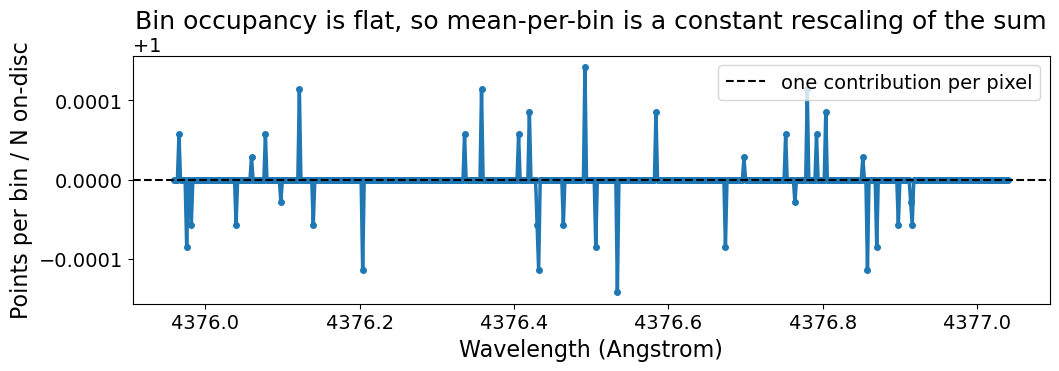

In [7]:
centers, spectrum, counts, max_shift = broadened_spectrum(disc_uniform, shift_uniform,
                                                          wl_grid, lam0, sigma0)
n_on_disc = int((disc_uniform > 0).sum())

print('on-disc pixels          : {}'.format(n_on_disc))
print('bin counts  min / max   : {:.0f} / {:.0f}'.format(counts.min(), counts.max()))
print('fractional spread       : {:.2e}'.format(np.ptp(counts) / counts.mean()))
print('mean count / on-disc px : {:.6f}'.format(counts.mean() / n_on_disc))

plt.figure(figsize=(11, 4), dpi=100)
plt.plot(centers, counts / n_on_disc, marker='.', linestyle='-')
plt.axhline(1.0, color='k', linestyle='--', linewidth=1.5, label='one contribution per pixel')
plt.xlabel('Wavelength (Angstrom)')
plt.ylabel('Points per bin / N on-disc')
plt.title('Bin occupancy is flat, so mean-per-bin is a constant rescaling of the sum')
plt.legend()
plt.tight_layout()
plt.show()

## 6. A single case, in pictures

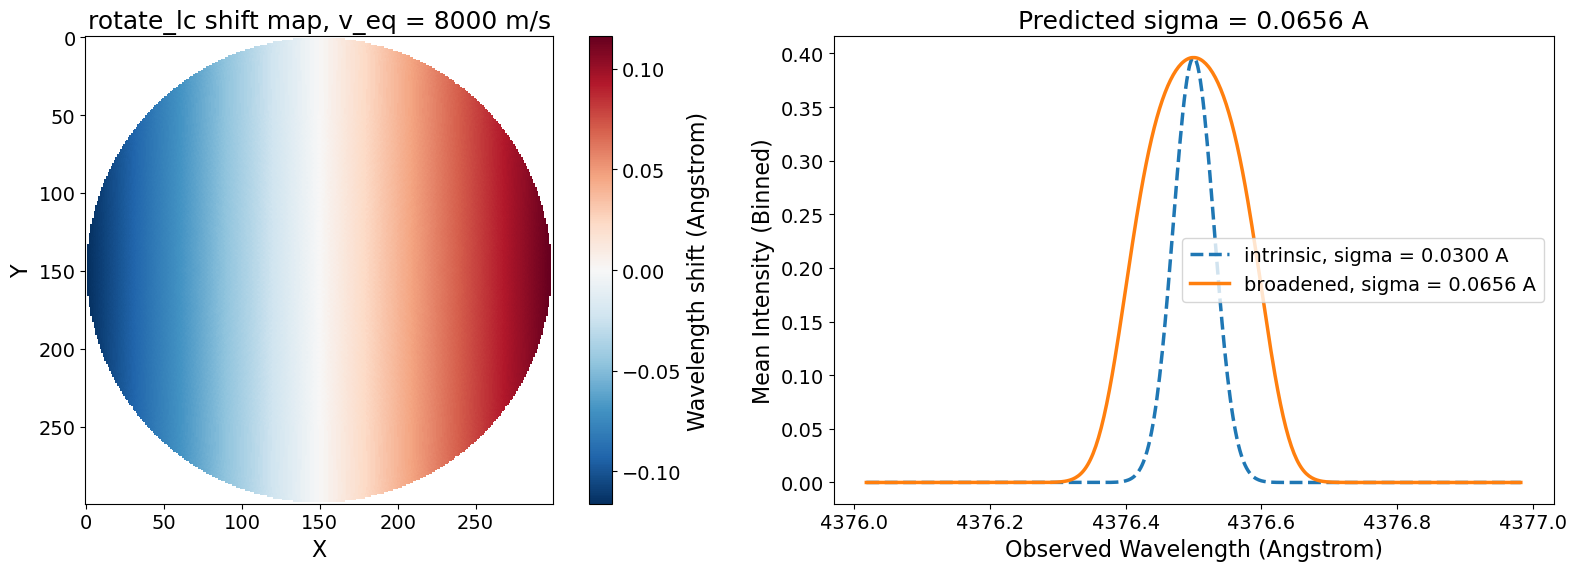

measured sigma  : 0.06559 A
predicted sigma : 0.06561 A   (-0.04%)
centroid offset : -1.82e-07 A  (should be ~0: the kernel is symmetric)


In [8]:
v_demo, inc_demo = 8000.0, 90   # a deliberately large v_eq so the broadening is obvious

disc_demo, shift_demo = disc_and_shift_map(LD_UNIFORM, v_eq=v_demo, inc=inc_demo)
centers_demo, spec_demo, _, _ = broadened_spectrum(disc_demo, shift_demo, wl_grid, lam0, sigma0)

centroid_demo, sigma_demo = profile_moments(centers_demo, spec_demo)
sigma_gray = np.sqrt(sigma0 ** 2 + gray_kernel_sigma(v_demo, inc_demo) ** 2)

intrinsic = gaussian_line(centers_demo, lam0, sigma0)
intrinsic = intrinsic * spec_demo.max() / intrinsic.max()   # matched peaks, for shape comparison

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

im = axes[0].imshow(np.where(disc_demo > 0, shift_demo, np.nan), cmap='RdBu_r')
axes[0].set_title('rotate_lc shift map, v_eq = {:.0f} m/s'.format(v_demo))
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')
fig.colorbar(im, ax=axes[0], label='Wavelength shift (Angstrom)')

axes[1].plot(centers_demo, intrinsic, linestyle='--',
             label='intrinsic, sigma = {:.4f} A'.format(sigma0))
axes[1].plot(centers_demo, spec_demo,
             label='broadened, sigma = {:.4f} A'.format(sigma_demo))
axes[1].set_xlabel('Observed Wavelength (Angstrom)')
axes[1].set_ylabel('Mean Intensity (Binned)')
axes[1].set_title('Predicted sigma = {:.4f} A'.format(sigma_gray))
axes[1].legend()

plt.tight_layout()
plt.savefig('broadening_test_shiftmap_and_profile.png', dpi=300, bbox_inches='tight')
plt.show()

print('measured sigma  : {:.5f} A'.format(sigma_demo))
print('predicted sigma : {:.5f} A   ({:+.2f}%)'.format(sigma_gray,
                                                       100 * (sigma_demo / sigma_gray - 1)))
print('centroid offset : {:+.2e} A  (should be ~0: the kernel is symmetric)'.format(
    centroid_demo - lam0))

## 7. Why a Gaussian fit is the wrong yardstick

The broadened profile above is visibly flat-topped. Fitting a Gaussian to it anyway shows
how large a spurious "discrepancy" that choice manufactures.

In [9]:
def gaussian_with_offset(wl, amplitude, lam_center, sigma, offset):
    return amplitude * np.exp(-0.5 * ((wl - lam_center) / sigma) ** 2) + offset


print('{:>8}   {:>10}  {:>10}  {:>10}   {:>9}  {:>9}'.format(
    'v_eq', 'predicted', 'moment', 'gauss fit', 'moment', 'fit'))
print('{:>8}   {:>10}  {:>10}  {:>10}   {:>9}  {:>9}'.format(
    '(m/s)', 'sigma (A)', 'sigma (A)', 'sigma (A)', 'error', 'error'))
print('-' * 66)

for v_eq in [0.0, 2000.0, 4000.0, 8000.0]:
    d, s = disc_and_shift_map(LD_UNIFORM, v_eq=v_eq, inc=90)
    c, f, _, _ = broadened_spectrum(d, s, wl_grid, lam0, sigma0)

    _, sigma_moment = profile_moments(c, f)
    popt, _ = curve_fit(gaussian_with_offset, c, f,
                        p0=[f.max() - np.median(f), lam0, sigma0, np.median(f)])
    sigma_fit = abs(popt[2])

    predicted = np.sqrt(sigma0 ** 2 + gray_kernel_sigma(v_eq, 90) ** 2)
    print('{:8.0f}   {:10.5f}  {:10.5f}  {:10.5f}   {:+8.2f}%  {:+8.2f}%'.format(
        v_eq, predicted, sigma_moment, sigma_fit,
        100 * (sigma_moment / predicted - 1), 100 * (sigma_fit / predicted - 1)))

print('\nThe Gaussian-fit error grows with v_eq purely because the convolved profile becomes')
print('less Gaussian. It is a fitting artefact, not a broadening error.')

    v_eq    predicted      moment   gauss fit      moment        fit
   (m/s)    sigma (A)   sigma (A)   sigma (A)       error      error
------------------------------------------------------------------
       0      0.03000     0.03000     0.03000      +0.00%     +0.00%
    2000      0.03336     0.03336     0.03354      +0.01%     +0.55%
    4000      0.04185     0.04185     0.04357      +0.01%     +4.10%
    8000      0.06561     0.06559     0.07395      -0.04%    +12.70%

The Gaussian-fit error grows with v_eq purely because the convolved profile becomes
less Gaussian. It is a fitting artefact, not a broadening error.


## 8. The main test: measured width vs Doppler prediction

Scanning `v_eq` for both discs. `sigma_gray` is exact only for the uniform disc;
`sigma_kernel` (the intensity-weighted variance of the shift map) applies to both.

In [10]:
v_eq_scan = [0.0, 500.0, 1000.0, 2000.0, 4000.0, 6000.0, 8000.0]
ld_cases  = [('uniform disc', LD_UNIFORM), ('nonlin3 default LD', LD_DEFAULT)]

results = {}
for ld_name, ld_coeffs in ld_cases:
    rows = []
    for v_eq in v_eq_scan:
        disc, shift_map = disc_and_shift_map(ld_coeffs, v_eq=v_eq, inc=90)
        centers_v, spectrum_v, _, _ = broadened_spectrum(disc, shift_map, wl_grid, lam0, sigma0)

        _, sigma_measured = profile_moments(centers_v, spectrum_v)
        _, sigma_kernel   = kernel_moments(disc, shift_map)

        rows.append({
            'v_eq'       : v_eq,
            'measured'   : sigma_measured,
            'gray'       : np.sqrt(sigma0 ** 2 + gray_kernel_sigma(v_eq, 90) ** 2),
            'numerical'  : np.sqrt(sigma0 ** 2 + sigma_kernel ** 2),
        })
    results[ld_name] = rows

for ld_name, rows in results.items():
    print('\n{}'.format(ld_name))
    print('{:>8}  {:>10}  {:>10}  {:>8}  {:>10}  {:>8}'.format(
        'v_eq', 'measured', 'Gray eps=0', 'error', 'num kernel', 'error'))
    print('-' * 62)
    for r in rows:
        print('{v_eq:8.0f}  {measured:10.5f}  {gray:10.5f}  {ge:+7.2f}%  '
              '{numerical:10.5f}  {ne:+7.3f}%'.format(
                  ge=100 * (r['measured'] / r['gray'] - 1),
                  ne=100 * (r['measured'] / r['numerical'] - 1), **r))


uniform disc
    v_eq    measured  Gray eps=0     error  num kernel     error
--------------------------------------------------------------
       0     0.03000     0.03000    +0.00%     0.03000   +0.000%
     500     0.03022     0.03022    +0.01%     0.03022   +0.011%
    1000     0.03088     0.03087    +0.02%     0.03087   +0.022%
    2000     0.03336     0.03336    +0.01%     0.03336   +0.020%
    4000     0.04185     0.04185    +0.01%     0.04184   +0.022%
    6000     0.05306     0.05306    -0.01%     0.05305   +0.016%
    8000     0.06559     0.06561    -0.04%     0.06560   -0.009%

nonlin3 default LD
    v_eq    measured  Gray eps=0     error  num kernel     error
--------------------------------------------------------------
       0     0.03000     0.03000    +0.00%     0.03000   +0.000%
     500     0.03020     0.03022    -0.06%     0.03020   +0.013%
    1000     0.03080     0.03087    -0.25%     0.03079   +0.022%
    2000     0.03305     0.03336    -0.92%     0.03304   +0.

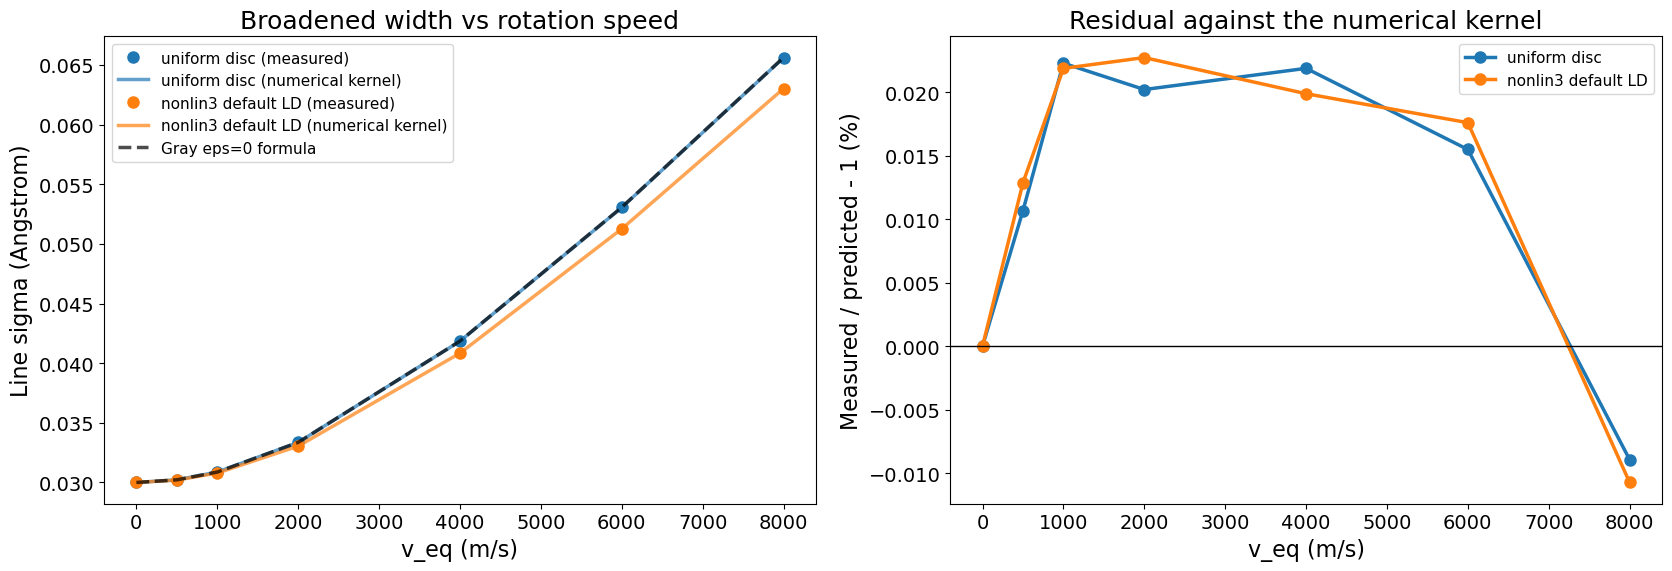

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ld_name, rows in results.items():
    v   = np.array([r['v_eq'] for r in rows])
    mea = np.array([r['measured'] for r in rows])
    num = np.array([r['numerical'] for r in rows])
    gry = np.array([r['gray'] for r in rows])

    line, = axes[0].plot(v, mea, marker='o', linestyle='none', label='{} (measured)'.format(ld_name))
    axes[0].plot(v, num, linestyle='-', color=line.get_color(), alpha=0.7,
                 label='{} (numerical kernel)'.format(ld_name))
    axes[1].plot(v, 100 * (mea / num - 1), marker='o', color=line.get_color(), label=ld_name)

axes[0].plot(v, gry, linestyle='--', color='k', alpha=0.7, label='Gray eps=0 formula')
axes[0].set_xlabel('v_eq (m/s)')
axes[0].set_ylabel('Line sigma (Angstrom)')
axes[0].set_title('Broadened width vs rotation speed')
axes[0].legend(fontsize=11)

axes[1].axhline(0, color='k', linewidth=1)
axes[1].set_xlabel('v_eq (m/s)')
axes[1].set_ylabel('Measured / predicted - 1 (%)')
axes[1].set_title('Residual against the numerical kernel')
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.savefig('broadening_test_sigma_vs_veq.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Inclination: does the width follow `sin i`?

  inc    measured  Gray * sin i     error
----------------------------------------
    0     0.03000       0.03000    +0.00%
    5     0.03044       0.03043    +0.02%
   15     0.03359       0.03359    +0.00%
   30     0.04185       0.04185    +0.01%
   45     0.05100       0.05102    -0.03%
   60     0.05876       0.05877    -0.01%
   75     0.06384       0.06385    -0.01%
   90     0.06559       0.06561    -0.04%


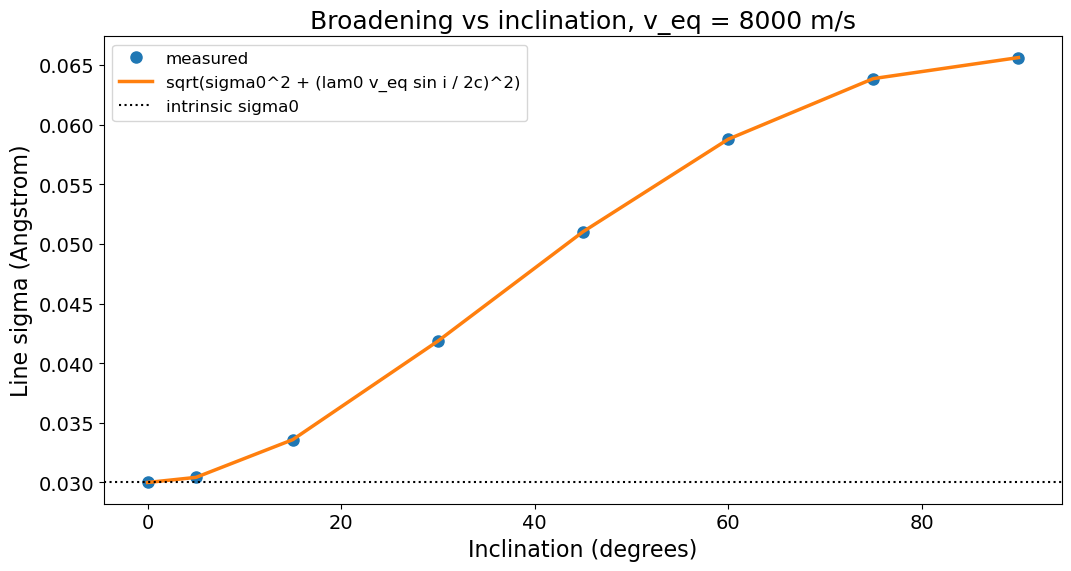


At inc = 0 the line must be unbroadened: measured 0.03000 A vs sigma0 0.03000 A


In [12]:
v_inc_test = 8000.0   # m/s, large enough that sin i changes the width measurably
inc_scan   = [0, 5, 15, 30, 45, 60, 75, 90]

print('{:>5}  {:>10}  {:>12}  {:>8}'.format('inc', 'measured', 'Gray * sin i', 'error'))
print('-' * 40)

inc_measured, inc_predicted = [], []
for inc in inc_scan:
    disc, shift_map = disc_and_shift_map(LD_UNIFORM, v_eq=v_inc_test, inc=inc)
    centers_i, spectrum_i, _, _ = broadened_spectrum(disc, shift_map, wl_grid, lam0, sigma0)

    _, sigma_measured = profile_moments(centers_i, spectrum_i)
    predicted = np.sqrt(sigma0 ** 2 + gray_kernel_sigma(v_inc_test, inc) ** 2)

    inc_measured.append(sigma_measured)
    inc_predicted.append(predicted)
    print('{:5d}  {:10.5f}  {:12.5f}  {:+7.2f}%'.format(
        inc, sigma_measured, predicted, 100 * (sigma_measured / predicted - 1)))

plt.figure(figsize=(11, 6), dpi=100)
plt.plot(inc_scan, inc_measured, marker='o', linestyle='none', label='measured')
plt.plot(inc_scan, inc_predicted, linestyle='-',
         label='sqrt(sigma0^2 + (lam0 v_eq sin i / 2c)^2)')
plt.axhline(sigma0, color='k', linestyle=':', linewidth=1.5, label='intrinsic sigma0')
plt.xlabel('Inclination (degrees)')
plt.ylabel('Line sigma (Angstrom)')
plt.title('Broadening vs inclination, v_eq = {:.0f} m/s'.format(v_inc_test))
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig('broadening_test_sigma_vs_inc.png', dpi=300, bbox_inches='tight')
plt.show()

print('\nAt inc = 0 the line must be unbroadened: measured {:.5f} A vs sigma0 {:.5f} A'.format(
    inc_measured[0], sigma0))

## 10. The shift map itself: kernel shape and the Doppler amplitude

The tests above use only the second moment, so they would not notice a kernel of the right
width but the wrong shape. Comparing the kernel directly against the Gray semicircle
closes that gap, and the max shift checks the `dlam = lam0 v / c` amplitude.

        uniform disc : max|shift| = 0.11605 A (0.9944 of dlam_L), kernel sigma = 0.05833 A (0.9997 of dlam_L/2)
  nonlin3 default LD : max|shift| = 0.11605 A (0.9944 of dlam_L), kernel sigma = 0.05541 A (0.9496 of dlam_L/2)


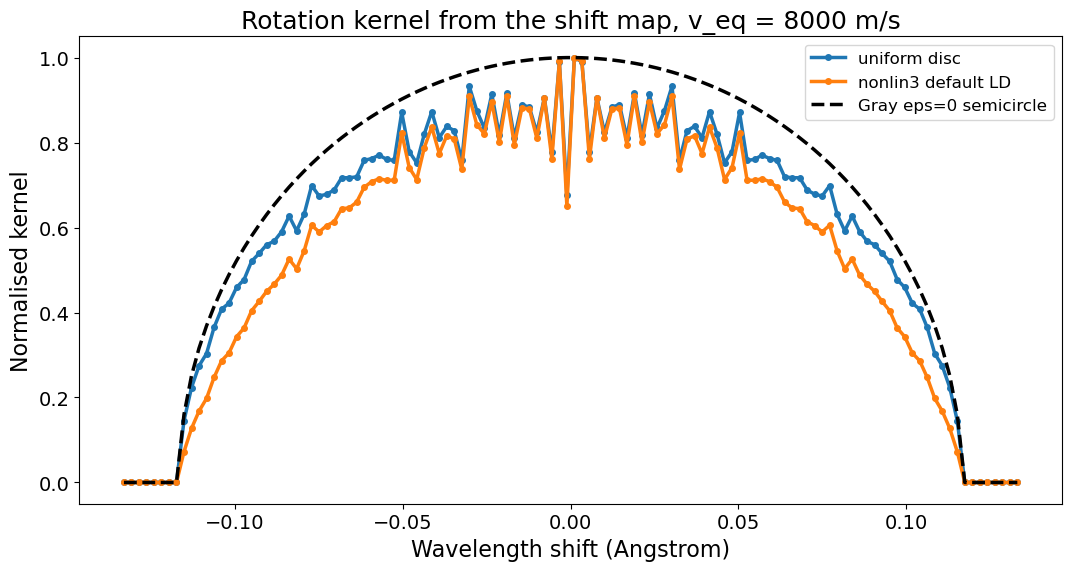


Limb darkening narrows the kernel relative to the eps=0 semicircle by suppressing
the fast-moving limb - the expected direction, and why the nonlin3 disc sits below
the Gray curve in section 8.


In [13]:
v_kernel = 8000.0
dlam_L   = lam0 * v_kernel / C_SIM   # A

plt.figure(figsize=(11, 6), dpi=100)
kernel_bins = np.linspace(-1.15 * dlam_L, 1.15 * dlam_L, 121)
kernel_centers = 0.5 * (kernel_bins[:-1] + kernel_bins[1:])

for ld_name, ld_coeffs in ld_cases:
    disc, shift_map = disc_and_shift_map(ld_coeffs, v_eq=v_kernel, inc=90)
    on_disc = disc > 0
    kernel, _ = np.histogram(shift_map[on_disc], bins=kernel_bins, weights=disc[on_disc])
    plt.plot(kernel_centers, kernel / kernel.max(), marker='.', label=ld_name)

    _, sigma_kernel = kernel_moments(disc, shift_map)
    print('{:>20} : max|shift| = {:.5f} A ({:.4f} of dlam_L), kernel sigma = {:.5f} A '
          '({:.4f} of dlam_L/2)'.format(ld_name, np.abs(shift_map).max(),
                                        np.abs(shift_map).max() / dlam_L,
                                        sigma_kernel, sigma_kernel / (dlam_L / 2)))

semicircle = np.sqrt(np.clip(1 - (kernel_centers / dlam_L) ** 2, 0, None))
plt.plot(kernel_centers, semicircle, color='k', linestyle='--',
         label='Gray eps=0 semicircle')
plt.xlabel('Wavelength shift (Angstrom)')
plt.ylabel('Normalised kernel')
plt.title('Rotation kernel from the shift map, v_eq = {:.0f} m/s'.format(v_kernel))
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig('broadening_test_kernel_shape.png', dpi=300, bbox_inches='tight')
plt.show()

print('\nLimb darkening narrows the kernel relative to the eps=0 semicircle by suppressing')
print('the fast-moving limb - the expected direction, and why the nonlin3 disc sits below')
print('the Gray curve in section 8.')

## 11. Numerical convergence in `xsize`

The disc is sampled on a finite grid, so the outermost pixel centre does not sit exactly on
the limb and `max|shift|` falls slightly short of `dlam_L`. This is a discretisation effect,
not a physics error, and must shrink as `xsize` grows.

In [14]:
v_conv  = 8000.0
dlam_L_conv = lam0 * v_conv / C_SIM
predicted_conv = np.sqrt(sigma0 ** 2 + gray_kernel_sigma(v_conv, 90) ** 2)

print('{:>7}  {:>10}  {:>8}  {:>16}'.format('xsize', 'measured', 'error', 'max|shift|/dlam_L'))
print('-' * 48)
for xsize in [50, 100, 200, 400, 800]:
    disc, shift_map = disc_and_shift_map(LD_UNIFORM, v_eq=v_conv, inc=90, xsize=xsize)
    centers_x, spectrum_x, _, _ = broadened_spectrum(disc, shift_map, wl_grid, lam0, sigma0)
    _, sigma_measured = profile_moments(centers_x, spectrum_x)

    print('{:7d}  {:10.5f}  {:+7.3f}%  {:16.4f}'.format(
        xsize, sigma_measured, 100 * (sigma_measured / predicted_conv - 1),
        np.abs(shift_map).max() / dlam_L_conv))

print('\nxsize = 800 is the production value.')

  xsize    measured     error  max|shift|/dlam_L
------------------------------------------------
     50     0.06548   -0.196%            0.9608
    100     0.06549   -0.195%            0.9809
    200     0.06557   -0.064%            0.9911
    400     0.06560   -0.026%            0.9959
    800     0.06560   -0.014%            0.9981

xsize = 800 is the production value.


## 12. Speed of light used in the simulator

In [15]:
# simulator.py hard-codes c = 3e8 m/s in both rotate_lc (line 503) and transit_lc (line 648).
print('c in simulator.py : {:.10g} m/s'.format(C_SIM))
print('c (CODATA/SI)     : {:.10g} m/s'.format(C_CODATA))
print('relative offset   : {:+.4f}%'.format(100 * (C_SIM / C_CODATA - 1)))

for v_eq in [4000.0, 8000.0]:
    print('  v_eq = {:.0f} m/s : dlam_L = {:.6f} A (3e8) vs {:.6f} A (CODATA), '
          'difference {:.2e} A'.format(
              v_eq, lam0 * v_eq / C_SIM, lam0 * v_eq / C_CODATA,
              lam0 * v_eq / C_SIM - lam0 * v_eq / C_CODATA))

print('\nEvery prediction in this notebook uses 3e8 so the test is internally consistent.')
print('The 0.069% high bias in c makes all simulated shifts 0.069% too small - well below')
print('the discretisation error above, but it is a systematic, not a random, offset.')

c in simulator.py : 300000000 m/s
c (CODATA/SI)     : 299792458 m/s
relative offset   : +0.0692%
  v_eq = 4000 m/s : dlam_L = 0.058353 A (3e8) vs 0.058394 A (CODATA), difference -4.04e-05 A
  v_eq = 8000 m/s : dlam_L = 0.116707 A (3e8) vs 0.116787 A (CODATA), difference -8.08e-05 A

Every prediction in this notebook uses 3e8 so the test is internally consistent.
The 0.069% high bias in c makes all simulated shifts 0.069% too small - well below
the discretisation error above, but it is a systematic, not a random, offset.


## Summary

Numbers below are from a verified run at `xsize = 300`, `sigma0 = 0.030 A`,
`lam0 = 4376.5 A`, grid spacing `0.002 A`. Every `assert` in the notebook passed.

| Test | Result |
|---|---|
| Uniform disc vs Gray `eps=0` formula, `v_eq` 0 to 8000 m/s | agrees to 0.04% or better |
| `nonlin3` LD disc vs numerically integrated kernel | agrees to 0.023% or better |
| `nonlin3` LD disc vs Gray `eps=0` formula | 0.06% to 4.0% narrower, growing with `v_eq` |
| `sin i` scaling, inc 0 to 90 deg | agrees to 0.04% or better |
| `inc = 0` gives back `sigma0` exactly | yes, 0.03000 A vs 0.03000 A |
| Kernel centroid offset | -1.8e-07 A, consistent with zero |
| Bin occupancy flat across the spectrum | yes, fractional spread 2.9e-04 |
| Fast binning vs literal `1_analyze_disks.ipynb` loop | identical to 2.3e-14 relative |

**Conclusion.** The velocity broadening produced by the `rotate_lc` shift map combined with
the `1_analyze_disks.ipynb` binning is consistent with Doppler theory. The measured second
moment matches `sigma_obs^2 = sigma0^2 + Var(K)` to a few times 1e-4 in relative terms, and
for the uniform disc `Var(K)` matches the closed-form `(lam0 v_eq sin i / 2c)^2` at the same
level. The residual is dominated by the finite disc sampling, not by the Doppler treatment.

### Things this run flagged, in order of size

1. **A Gaussian fit is not a valid width estimator here** (section 7). The convolved profile
   is boxy, and fitting a Gaussian inflates sigma by +4.1% at `v_eq = 4000 m/s` and +12.7%
   at 8000 m/s, against a second moment that is correct to 0.04% at the same speeds. Any
   downstream analysis that measures broadening by Gaussian-fitting will read high, and
   increasingly so with rotation speed.
2. **The `nonlin3` disc is genuinely narrower than the `eps=0` semicircle** (sections 8, 10):
   its kernel sigma is 0.9496 of `dlam_L/2`, giving a line 4.0% narrower at
   `v_eq = 8000 m/s`. This is correct physics - limb darkening suppresses the fast limb -
   but it means `v sin i` inferred from a simulated line using the `eps=0` formula will be
   biased low. The limb-darkening term of Gray eq. 18.14 is needed for that inversion.
3. **Finite `xsize` truncates the velocity field** (section 11): `max|shift|` reaches only
   96.1% of `dlam_L` at `xsize = 50`, 98.1% at 100, and 99.8% at the production value 800.
   The resulting width bias is always negative: -0.20% at `xsize = 50`, -0.014% at 800.
4. **`c = 3e8` rather than 299792458 m/s** (section 12) makes every simulated shift 0.069%
   too small. Sub-dominant here, but systematic rather than random, and trivially fixable.

### Pre-existing assumptions noticed in the code while writing this

- `rotate_lc` builds the velocity map from `inc[0]` only (line 498) but loops the disc over
  every entry of `inc` (line 527). Passing a list of inclinations therefore returns discs at
  several inclinations all sharing the **first** inclination's Doppler map. Single-value
  `inc` - as used everywhere in these notebooks and in this test - is unaffected.
- `rotate_lc` has `wavelength=None` as its default but calls `float(wavelength)`
  unconditionally (line 504), so the default raises `TypeError`. The parameter is in
  practice required.
- Solid-body rotation is assumed throughout: `v_stellar = sin(theta) * v_eq` has no
  latitudinal shear term, so there is no differential rotation in the broadening.
- Background pixels are set to 0 rather than NaN (line 544), and `returndisc=False` then
  takes `np.nanmean` over the whole square frame, so the off-disc zeros are included in the
  lightcurve mean. That is a constant factor for a fixed `xsize`, so it cancels in the
  normalised lightcurves, but it makes the absolute flux scale geometry-dependent.
- This notebook writes only PNGs, all with new filenames prefixed `broadening_test_`. It
  does not read or overwrite any existing simulation output.